In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [39]:
df = pd.read_csv("winemag-data-130k-v2.csv")
df.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent.sort_values(ascending=False)

region_2                 61.136715
designation              28.825661
taster_twitter_handle    24.015357
taster_name              20.192197
region_1                 16.347493
price                     6.921544
province                  0.048472
country                   0.048472
variety                   0.000769
Unnamed: 0                0.000000
points                    0.000000
description               0.000000
title                     0.000000
winery                    0.000000
dtype: float64

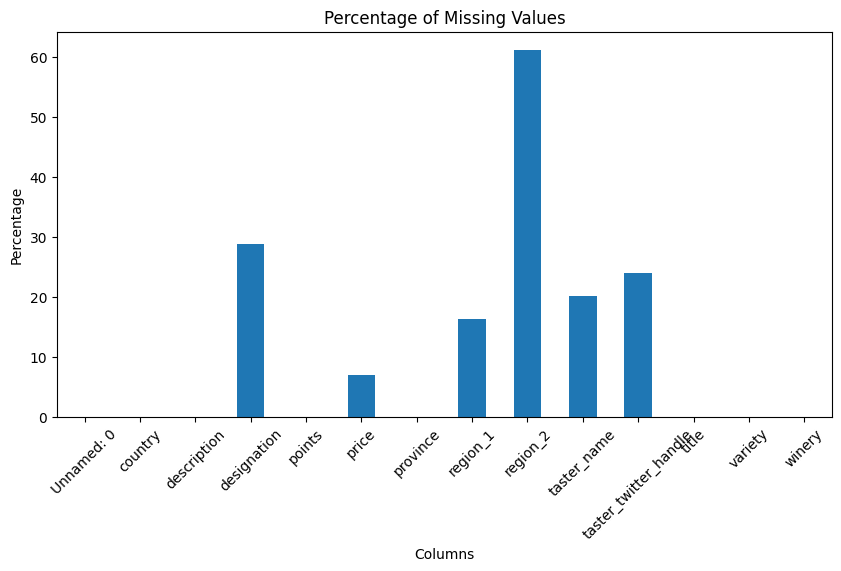

In [ ]:
import matplotlib.pyplot as plt

missing_percent.plot(kind='bar', figsize=(10,5))

plt.title("Percentage of Missing Values")
plt.ylabel("Percentage")
plt.xlabel("Columns")
plt.xticks(rotation=45)

plt.show()

In [ ]:
df_mean = df.copy()
df_median = df.copy()
df_mode = df.copy()

In [ ]:
num_cols = df_mean.select_dtypes(include='number').columns

for col in num_cols:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

df_mean.isnull().sum()

Unnamed: 0                   0
country                     63
description                  0
designation              37465
points                       0
price                        0
province                    63
region_1                 21247
region_2                 79460
taster_name              26244
taster_twitter_handle    31213
title                        0
variety                      1
winery                       0
dtype: int64

In [ ]:
cat_cols = df_mean.select_dtypes(include='object').columns

for col in cat_cols:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mode()[0])

df_mean.isnull().sum()

Unnamed: 0               0
country                  0
description              0
designation              0
points                   0
price                    0
province                 0
region_1                 0
region_2                 0
taster_name              0
taster_twitter_handle    0
title                    0
variety                  0
winery                   0
dtype: int64

In [ ]:
df_median = df.copy()

num_cols = df_median.select_dtypes(include='number').columns

for col in num_cols:
    df_median[col] = df_median[col].fillna(df_median[col].median())

cat_cols = df_median.select_dtypes(include='object').columns

for col in cat_cols:
    df_median[col] = df_median[col].fillna(df_median[col].mode()[0])

df_median.isnull().sum()

Unnamed: 0               0
country                  0
description              0
designation              0
points                   0
price                    0
province                 0
region_1                 0
region_2                 0
taster_name              0
taster_twitter_handle    0
title                    0
variety                  0
winery                   0
dtype: int64

In [ ]:
df_mode = df.copy()

for col in df_mode.columns:
    df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])

df_mode.isnull().sum()

Unnamed: 0               0
country                  0
description              0
designation              0
points                   0
price                    0
province                 0
region_1                 0
region_2                 0
taster_name              0
taster_twitter_handle    0
title                    0
variety                  0
winery                   0
dtype: int64

In [ ]:
num_cols = df.select_dtypes(include='number').columns

comparison = pd.DataFrame({
    "Original Mean": df[num_cols].mean(),
    "Mean Imputation": df_mean[num_cols].mean(),
    "Median Imputation": df_median[num_cols].mean(),
    "Mode Imputation": df_mode[num_cols].mean()
})

comparison

,Original Mean,Mean Imputation,Median Imputation,Mode Imputation
Unnamed: 0,64985.000000,64985.000000,64985.000000,64985.000000
points,88.447138,88.447138,88.447138,88.447138
price,35.363389,35.363389,34.646083,34.300005


In [ ]:
std_comparison = pd.DataFrame({
    "Original": df[num_cols].std(),
    "Mean": df_mean[num_cols].std(),
    "Median": df_median[num_cols].std(),
    "Mode": df_mode[num_cols].std()
})

std_comparison

,Original,Mean,Median,Mode
Unnamed: 0,37519.540256,37519.540256,37519.540256,37519.540256
points,3.039730,3.039730,3.039730,3.039730
price,41.022218,39.577066,39.664385,39.768715


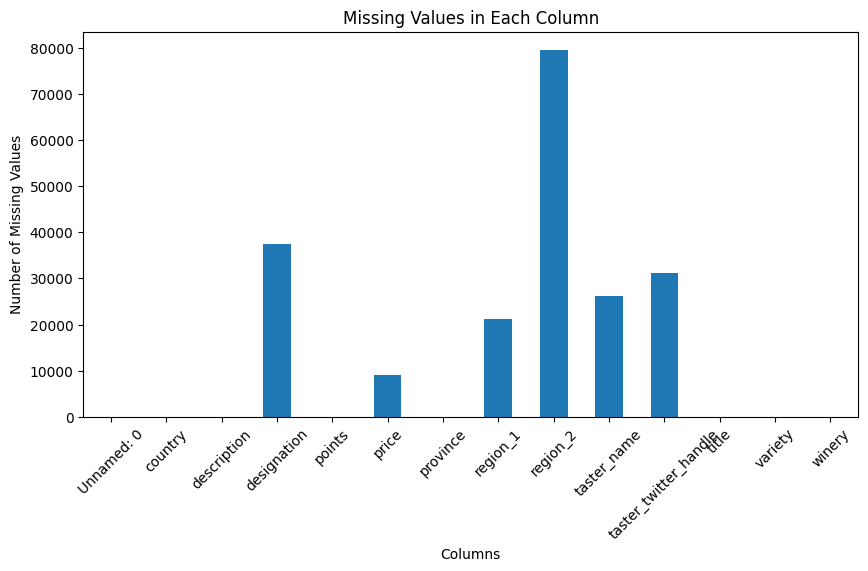

In [ ]:
missing_values = df.isnull().sum()

plt.figure(figsize=(10,5))
missing_values.plot(kind='bar')

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.show()

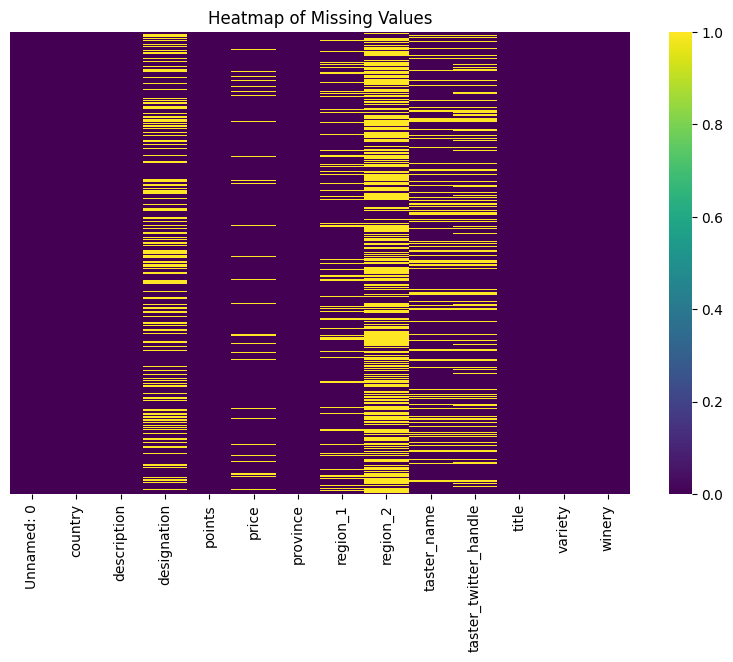

In [43]:
import seaborn as sns

plt.figure(figsize=(10,6))

sns.heatmap(
    df.isnull(),
    cbar=True,
    cmap='viridis',
    yticklabels=False
)

plt.title("Heatmap of Missing Values")
plt.show()

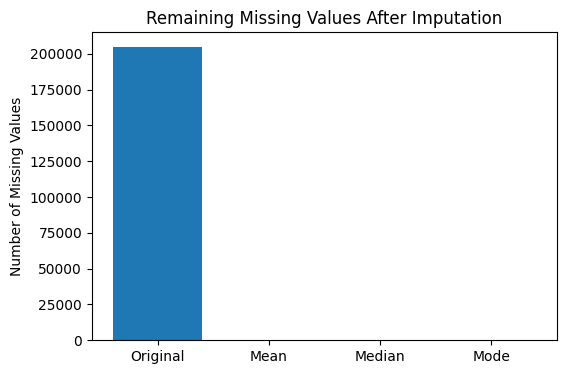

In [44]:
comparison = {
    "Original": df.isnull().sum().sum(),
    "Mean": df_mean.isnull().sum().sum(),
    "Median": df_median.isnull().sum().sum(),
    "Mode": df_mode.isnull().sum().sum()
}

plt.figure(figsize=(6,4))
plt.bar(comparison.keys(), comparison.values())

plt.title("Remaining Missing Values After Imputation")
plt.ylabel("Number of Missing Values")

plt.show()

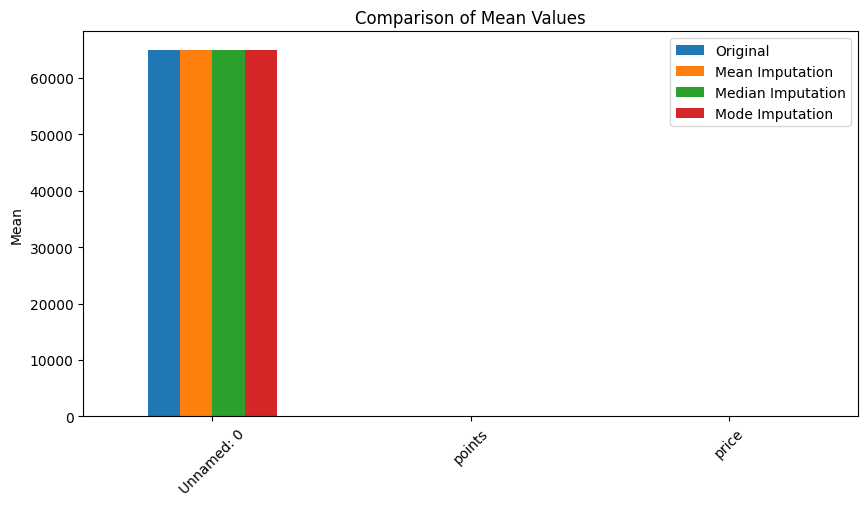

In [ ]:
comparison_mean = pd.DataFrame({
    'Original': df[num_cols].mean(),
    'Mean Imputation': df_mean[num_cols].mean(),
    'Median Imputation': df_median[num_cols].mean(),
    'Mode Imputation': df_mode[num_cols].mean()
})

comparison_mean.plot(kind='bar', figsize=(10,5))

plt.title("Comparison of Mean Values")
plt.ylabel("Mean")
plt.xticks(rotation=45)

plt.show()

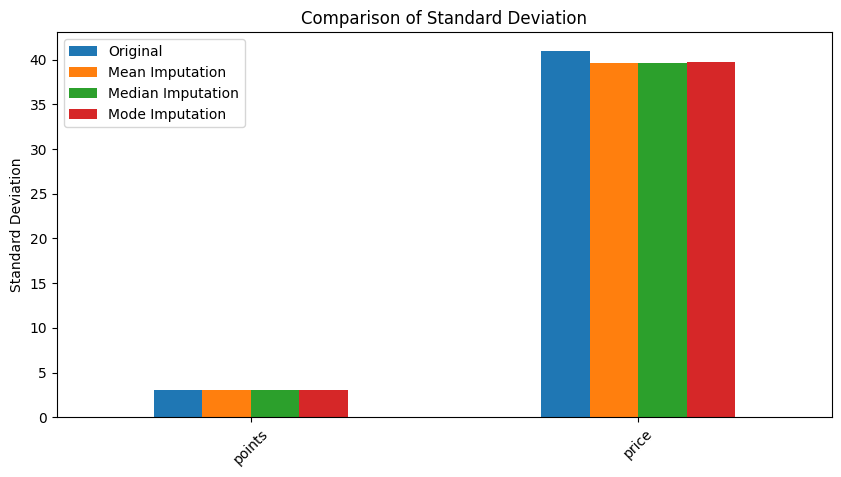

In [ ]:
comparison_std = pd.DataFrame({
    'Original': df[plot_cols].std(),
    'Mean Imputation': df_mean[plot_cols].std(),
    'Median Imputation': df_median[plot_cols].std(),
    'Mode Imputation': df_mode[plot_cols].std()
})

comparison_std.plot(kind='bar', figsize=(10,5))

plt.title("Comparison of Standard Deviation")
plt.ylabel("Standard Deviation")
plt.xticks(rotation=45)

plt.show()